# Basketball: what controlled opponent adjustment actually changed

B003 completed real owner execution. This notebook inspects the audited aggregate evidence for NBA, NCAA men and NCAA women. It loads no individual games, private feature matrices or fitted assets and performs zero model fits. The invented contract walkthrough is a separate section.

[Study](../docs/BASKETBALL_FOUNDATION.md) · [Generated league tables](../docs/BASKETBALL_RESULTS.md) · [Model card](../docs/BASKETBALL_MODEL_CARD.md)

Historical 2025 and 2026 folds are development-exposed after selection. Statistical release times use an explicit 24-hour reconstruction assumption. T−60 and T−24h remain separate. No qualified MARKET advantage or prospective profit is established.

In [1]:
from pathlib import Path
import json, sys
from html import escape
from IPython.display import display, HTML, SVG
import plotly.graph_objects as go
from plotly.subplots import make_subplots
here=Path.cwd().resolve()
root=next(p for p in (here,*here.parents) if (p/'examples/basketball_contracts/evidence.py').is_file())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from examples.basketball_contracts.evidence import load_evidence, selected_season_rows
from examples.basketball_contracts.evidence_v2 import matched_selected_rows, NAMES
from examples.basketball_contracts.__main__ import walkthrough
evidence=load_evidence(root/'docs/evidence/2026-10-27-basketball-b003.json')
baseline=load_evidence(root/'docs/evidence/2026-10-27-basketball-b002.json')
owner=evidence['owner_execution']
print(json.dumps({k:owner[k] for k in ('completed_native_fit_units','imported_predecessor_units','verified_current_release_manifest_units','cumulative_basketball_native_units','current_forecast_rows','current_distinct_games','prior_pending_rows','actual_orders','profit')},indent=2))
assert owner['completed_native_fit_units']==60
assert owner['imported_predecessor_units']==156
assert owner['cumulative_basketball_native_units']==172+60
assert owner['actual_orders']==0 and owner['profit'] is None

def table(headers,rows):
    html='<table><thead><tr>'+''.join('<th>'+escape(str(v))+'</th>' for v in headers)+'</tr></thead><tbody>'
    html+=''.join('<tr>'+''.join('<td>'+escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</tbody></table>'
    display(HTML(html))

def show_figure(figure,description):
    display({'application/vnd.plotly.v1+json':json.loads(figure.to_json()),'text/plain':description},raw=True)

tracks={t['league']:t for t in evidence['tracks'] if t['horizon_minutes']==60}
colors={'nba':'#2457A7','ncaam':'#13796B','ncaaw':'#7D3E9D'}

{
  "completed_native_fit_units": 60,
  "imported_predecessor_units": 156,
  "verified_current_release_manifest_units": 216,
  "cumulative_basketball_native_units": 232,
  "current_forecast_rows": 110,
  "current_distinct_games": 61,
  "prior_pending_rows": 110,
  "actual_orders": 0,
  "profit": null
}


## Selected probability models: preserve both seasons

NBA keeps the earlier strength logistic model. Both college tracks select rich combined logistic with 63 predictors on the declared historical criterion. The full basketball cohorts below must not be compared with MARKET scores from different games. Separate point forecasts use Ridge and do not supply calibrated score intervals.

In [2]:
selected=selected_season_rows(evidence)
table(['League','Season','Games','Selected probability recipe','Log loss','Brier','Correct / incorrect','Fixed-bin ECE'],[[NAMES[r['league']],r['validation_season'],f"{r['n']:,}",r['recipe'],f"{r['log_loss']:.6f}",f"{r['brier']:.6f}",f"{r['correct']:,} / {r['incorrect']:,}",f"{r['ece_10_fixed_bins']:.6f}"] for r in selected])
assert len(selected)==6
assert all(t['prior_controls_unchanged'] for t in tracks.values())

League,Season,Games,Selected probability recipe,Log loss,Brier,Correct / incorrect,Fixed-bin ECE
NBA,2025,"1,248",basketball_strength,0.612542,0.212630,811 / 437,0.030820
NBA,2026,"1,249",basketball_strength,0.602398,0.207240,846 / 403,0.030582
NCAA men,2025,"5,758",basketball_rich_combined,0.524171,0.177207,"4,168 / 1,590",0.014386
NCAA men,2026,"5,749",basketball_rich_combined,0.526661,0.178728,"4,138 / 1,611",0.023588
NCAA women,2025,"5,280",basketball_rich_combined,0.455769,0.151592,"4,022 / 1,258",0.024878
NCAA women,2026,"5,621",basketball_rich_combined,0.458433,0.152452,"4,286 / 1,335",0.022670


## Controlled comparisons: what does the added representation contribute?

Negative differences favor the B003 arm. Each point is a paired pooled comparison with the exact specified earlier architecture; the bars show descriptive 95% seven-day-block intervals. Both seasons and their separate intervals remain in the export. College improvements persist across both seasons. NBA's new arms do not beat its previous strength selection.

The intervals are development summaries after selection, not untouched confirmation or a multiplicity-adjusted discovery claim. Comparisons against a baseline that was not the league champion do not imply a new champion.

Paired historical control contrasts, with descriptive intervals.

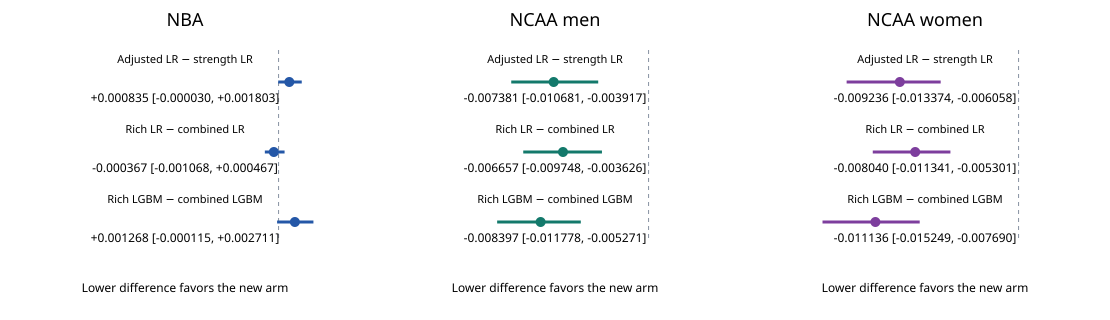

In [3]:
pairs=[('basketball_opponent_adjusted','basketball_strength','Adjusted LR − strength LR'),('basketball_rich_combined','basketball_combined','Rich LR − combined LR'),('basketball_rich_lightgbm','basketball_lightgbm','Rich LGBM − combined LGBM')]
fig=make_subplots(rows=1,cols=3,subplot_titles=[NAMES[k] for k in ('nba','ncaam','ncaaw')],shared_yaxes=True)
svg=['<svg xmlns="http://www.w3.org/2000/svg" width="1110" height="320" viewBox="0 0 1110 320"><rect width="1110" height="320" fill="white"/>']
for col,league in enumerate(('nba','ncaam','ncaaw'),1):
    comparisons=[next(r for r in tracks[league]['paired_control_comparisons'] if (r['arm'],r['control'],r['season'])==(a,b,'pooled')) for a,b,label in pairs]
    xs=[r['delta_log_loss_a_minus_b'] for r in comparisons]
    fig.add_trace(go.Scatter(x=xs,y=[p[2] for p in pairs],mode='markers',marker={'size':10,'color':colors[league]},error_x={'type':'data','array':[r['ci95'][1]-x for r,x in zip(comparisons,xs)],'arrayminus':[x-r['ci95'][0] for r,x in zip(comparisons,xs)]},name=NAMES[league],showlegend=False,hovertemplate='%{y}<br>Δ log loss: %{x:.6f}<extra></extra>'),row=1,col=col)
    fig.add_vline(x=0,line_dash='dash',line_color='#8792A2',row=1,col=col)
    fig.update_xaxes(title_text='Δ log loss (lower favors new arm)',range=[-.017,.004],row=1,col=col)
    offset=(col-1)*370
    svg.append(f'<text x="{offset+185}" y="26" text-anchor="middle" font-family="sans-serif" font-size="18">{NAMES[league]}</text>')
    def sx(v):return offset+60+(v+.017)/.021*270
    zero=sx(0)
    svg.append(f'<line x1="{zero}" y1="50" x2="{zero}" y2="240" stroke="#8792A2" stroke-dasharray="4 4"/>')
    for i,(r,x) in enumerate(zip(comparisons,xs)):
        y=82+i*70;lo,hi=r['ci95']
        svg.append(f'<text x="{offset+185}" y="{y-19}" text-anchor="middle" font-family="sans-serif" font-size="11">{escape(pairs[i][2])}</text><line x1="{sx(lo)}" x2="{sx(hi)}" y1="{y}" y2="{y}" stroke="{colors[league]}" stroke-width="3"/><circle cx="{sx(x)}" cy="{y}" r="5" fill="{colors[league]}"/><text x="{offset+185}" y="{y+20}" text-anchor="middle" font-family="sans-serif" font-size="12">{x:+.6f} [{lo:+.6f}, {hi:+.6f}]</text>')
    svg.append(f'<text x="{offset+185}" y="292" text-anchor="middle" font-family="sans-serif" font-size="12">Lower difference favors the new arm</text>')
svg.append('</svg>')
fig.update_layout(height=360,width=1150,template='plotly_white',margin={'l':180,'r':30,'t':55,'b':65},title_text='B003 representations against exact B002 architecture controls')
show_figure(fig,'Paired historical control contrasts, with descriptive intervals.')
display(SVG(''.join(svg)))
controlled_figure_completed=True

## Calibration exposes a tradeoff hidden by one headline score

These pooled reliability curves compare each B003 historical selection with its B002 selection on the same full-cohort games. The diagonal means average predicted probability equals observed frequency. Binning is descriptive and does not recalibrate a model.

Men's ECE increases from 0.013393 to 0.014288; women's increases from 0.019232 to 0.023450 even as log loss and Brier improve. NBA's selected recipe is unchanged. This matters for interpreting probability confidence and motivates a separately validated calibration study.

In [4]:
fig=make_subplots(rows=1,cols=3,subplot_titles=[NAMES[k] for k in ('nba','ncaam','ncaaw')],shared_xaxes=True,shared_yaxes=True)
for col,league in enumerate(('nba','ncaam','ncaaw'),1):
    track=tracks[league]
    choice=next(s for s in track['selections'] if s['cohort']=='full_basketball')
    old=track['baseline_full_selection']['selected_recipe']
    new=choice['selected_recipe']
    for recipe,label,color,dash in [(old,'B002 selection','#7B8795','dash'),(new,'B003 selection',colors[league],'solid')]:
        row=next(r for r in choice['leaderboard'] if r['recipe']==recipe)
        bins=row['calibration_bins']
        fig.add_trace(go.Scatter(x=[b['mean_probability'] for b in bins],y=[b['observed_rate'] for b in bins],customdata=[b['n'] for b in bins],mode='lines+markers',name=f'{NAMES[league]} · {label}',line={'color':color,'dash':dash},hovertemplate='Mean p %{x:.3f}<br>Observed %{y:.3f}<br>Games %{customdata}<extra></extra>'),row=1,col=col)
    fig.add_trace(go.Scatter(x=[0,1],y=[0,1],mode='lines',line={'color':'#CDD2D8','dash':'dot'},showlegend=False,hoverinfo='skip'),row=1,col=col)
    fig.update_xaxes(title_text='Mean predicted probability',range=[0,1],row=1,col=col)
    fig.update_yaxes(title_text='Observed home-win frequency',range=[0,1],row=1,col=col)
fig.update_layout(height=430,width=1150,template='plotly_white',legend={'orientation':'h','y':-0.23},margin={'l':55,'r':20,'t':55,'b':100},title_text='Selected historical reliability: gains coexist with calibration weaknesses')
show_figure(fig,'Pooled selected-model reliability curves; no new calibration is fitted.')
calibration_figure_completed=True

Pooled selected-model reliability curves; no new calibration is fitted.

## More matched MARKET observations are not more earlier training data

The chart shows actual T−60 matched validation counts before and after recovery, separate by league and season. NCAA men's 2026 sample grows to 1,143 while 2025 remains empty. NBA is still sparse. Women's two-season support improves, but proper-score differences change sign across years and their intervals include zero.

Learned MARKET-only and integrated models still fail the earlier training-support requirement. Kalshi, Polymarket US and international Polymarket remain distinct unqualified comparators with zero admitted historical events and zero executable current quotes in B003. Displayed page prices are not fills.

In [5]:
fig=make_subplots(rows=1,cols=3,subplot_titles=[NAMES[k] for k in ('nba','ncaam','ncaaw')])
for col,league in enumerate(('nba','ncaam','ncaaw'),1):
    for source,label,color in [(baseline,'B002','#A6AFBD'),(evidence,'B003',colors[league])]:
        track=next(t for t in source['tracks'] if t['league']==league and t['horizon_minutes']==60)
        counts=[]
        for year in (2025,2026):
            matches=[r for r in track['season_scorecards'] if (r['cohort'],r['validation_season'],r['recipe'])==('matched_MARKET',year,'MARKET_raw')]
            counts.append(matches[0]['n'] if matches else 0)
        fig.add_trace(go.Bar(x=['2025','2026'],y=counts,name=f'{NAMES[league]} · {label}',marker_color=color,text=counts,textposition='outside'),row=1,col=col)
    fig.update_xaxes(title_text='Validation season ending',row=1,col=col)
    fig.update_yaxes(title_text='Matched validation games',rangemode='tozero',row=1,col=col)
fig.update_layout(height=420,width=1150,template='plotly_white',barmode='group',legend={'orientation':'h','y':-0.25},margin={'l':55,'r':25,'t':55,'b':100},title_text='Actual matched MARKET coverage after model-fold exclusions')
show_figure(fig,'Matched T60 validation coverage; league-specific scales.')
rows=[r for r in matched_selected_rows(evidence) if r['horizon_minutes']==60]
table(['League','Season','Matched games','Basketball log loss','MARKET log loss','Basketball − MARKET'],[[NAMES[r['league']],r['season'],r['n'],'Unavailable' if r['n']==0 else f"{r['model_log_loss']:.6f}",'Unavailable' if r['n']==0 else f"{r['market_log_loss']:.6f}",'Unavailable' if r['n']==0 else f"{r['difference']:+.6f}"] for r in rows])
assert evidence['evaluation']['market_advantage_established'] is False
market_figure_completed=True

Matched T60 validation coverage; league-specific scales.

League,Season,Matched games,Basketball log loss,MARKET log loss,Basketball − MARKET
NBA,2025,9,0.603386,0.504146,+0.099240
NBA,2026,16,0.645276,0.656242,-0.010966
NCAA men,2025,0,Unavailable,Unavailable,Unavailable
NCAA men,2026,1143,0.577570,0.567127,+0.010444
NCAA women,2025,149,0.430101,0.421845,+0.008256
NCAA women,2026,143,0.490909,0.501340,-0.010431


## Preserve reuse accounting and genuine prospective issuance

B003's 216 estimator manifests contain 60 new fits plus 156 imported aliases. The cumulative unique basketball total is 232. Reuse events are not additional training. Cumulative work remains charged across releases under the unchanged ceiling.

The exact 110 B002-issued forecasts remain pending at the B003 snapshot. B003 added 110 later forecast versions for the same 61 games, all early outlooks before their declared locks. No contemporary qualified MARKET probabilities or settled prospective outcomes were available. No trading or profit is inferred.

In [6]:
table(['Owner evidence','Observed value'],[
    ['New real estimator units',owner['completed_native_fit_units']],
    ['Imported prior units',owner['imported_predecessor_units']],
    ['Cumulative unique basketball units',owner['cumulative_basketball_native_units']],
    ['Additional active minutes',f"{owner['this_invocation_active_seconds_through_return_snapshot']/60:.2f}"],
    ['Remaining work seconds at returned snapshot',f"{owner['remaining_work_seconds_at_return_snapshot']:.2f}"],
    ['Prior immutable forecasts pending',owner['prior_pending_rows']],
    ['Distinct games in new early outlooks',owner['current_distinct_games']],
    ['Prospectively settled games',owner['prospectively_settled_games_at_issue']]])
assert owner['qualified_current_market_probabilities']==0
assert owner['prospectively_settled_games_at_issue']==0
assert owner['prior_pending_rows']==110

Owner evidence,Observed value
New real estimator units,60
Imported prior units,156
Cumulative unique basketball units,232
Additional active minutes,22.10
Remaining work seconds at returned snapshot,928.98
Prior immutable forecasts pending,110
Distinct games in new early outlooks,61
Prospectively settled games,0


## Separate invented contract walkthrough

The next cell uses invented identities and probabilities to test league separation, source clocks, stale-quote rejection and the protected 2027 selection boundary. Those Brier scores are software examples. They are not the real model results above.

In [7]:
synthetic=walkthrough()
assert synthetic['synthetic_only'] is True and synthetic['model_fits']==0
assert synthetic['protected_2027_selection_rejected'] is True
assert synthetic['network_calls']==synthetic['paid_requests']==synthetic['orders']==0
print(json.dumps({'synthetic_only':True,'model_fits':0,'protected_2027_selection_rejected':True,'invented_examples':[r['invented_score_demonstration'] for r in synthetic['reports']]},indent=2))

{
  "synthetic_only": true,
  "model_fits": 0,
  "protected_2027_selection_rejected": true,
  "invented_examples": [
    {
      "league": "nba",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "de62b4e01fafec0bfc63f0f5756a1caed8f8f5a0a4cdb11d8981f4c3308b0a0b",
      "profit": null,
      "profit_status": "unavailable_without_predecision_execution_and_settlement_evidence"
    },
    {
      "league": "ncaam",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "335b8ae2bb0e715002239420b57540642f81566f5f9f1ef518e07a1ac98a1954",
      "profit": null,
      "profit_status": "unavailable_without_predecision_execution_and_settlement_evidence"
    },
    {
      "league": "ncaaw",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "80c512c

## Decision and next milestone

Keep the previous NBA strength selection. Treat the college rich logistic models as stronger historical research candidates while explicitly tracking calibration weakness. Expanded MARKET observations do not establish an advantage or remove the earlier training gap. B004 owner execution is pending; exact feature reuse, historical point bias and uncertainty, data recovery and venue-separated exchange evidence are its next tests.

The final cell executes after all three figures. The notebook runner then saves, reopens and checks persistent native rich outputs and completion. No model is fitted, no private observation is loaded and no request is sent by this notebook.

In [8]:
assert controlled_figure_completed and calibration_figure_completed and market_figure_completed
assert owner['completed_native_fit_units']==60 and synthetic['model_fits']==0
assert evidence['evaluation']['current_outcomes_used_for_selection_or_fitting'] is False
assert evidence['next_release']['release']=='B004' and evidence['next_release']['owner_status']=='pending'
assert all(not v for v in evidence['publication_boundary'].values())
print('PUBLIC_REVIEW_COMPLETE: B003 aggregate evidence inspected; zero local model fits; three native figures and subsequent cells completed.')

PUBLIC_REVIEW_COMPLETE: B003 aggregate evidence inspected; zero local model fits; three native figures and subsequent cells completed.
